# Music Genre Classification - Exploratory Data Analysis (EDA)

## 1. Project Background
This notebook explores the pre-processed **GTZAN Genre Collection dataset** (`features_30_sec.csv`), where each row represents a 30-second audio track with extracted audio features (e.g., Chroma STFT, Spectral Centroid, Bandwidth, MFCCs, Tempo, Zero-Crossing Rate) and a target `label` indicating music genre.

### Objectives of this EDA:
1. Load and inspect the dataset structure.
2. Analyze the target variable (`label`) distribution.
3. Compute summary statistics and verify data integrity (check for missing values).
4. Visualize key feature distributions (histograms, box plots, correlation heatmaps) to understand musical patterns across genres.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Plotting configuration
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print("Libraries loaded successfully.")


Libraries loaded successfully.


## 2. Data Loading & Inspection
We load the pre-extracted 30-second feature dataset from `data/features_30_sec.csv`.


In [2]:
data_path = 'data/features_30_sec.csv' if os.path.exists('data/features_30_sec.csv') else '../data/features_30_sec.csv'
df = pd.read_csv(data_path)
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()


Dataset Shape: 1000 rows, 60 columns


,filename,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,...,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,label
0,blues.00000.wav,661794,0.350088,0.088757,0.130228,0.002827,1784.165850,129774.064525,2002.449060,85882.761315,...,52.420910,-1.690215,36.524071,-0.408979,41.597103,-2.303523,55.062923,1.221291,46.936035,blues
1,blues.00001.wav,661794,0.340914,0.094980,0.095948,0.002373,1530.176679,375850.073649,2039.036516,213843.755497,...,55.356403,-0.731125,60.314529,0.295073,48.120598,-0.283518,51.106190,0.531217,45.786282,blues
2,blues.00002.wav,661794,0.363637,0.085275,0.175570,0.002746,1552.811865,156467.643368,1747.702312,76254.192257,...,40.598766,-7.729093,47.639427,-1.816407,52.382141,-3.439720,46.639660,-2.231258,30.573025,blues
3,blues.00003.wav,661794,0.404785,0.093999,0.141093,0.006346,1070.106615,184355.942417,1596.412872,166441.494769,...,44.427753,-3.319597,50.206673,0.636965,37.319130,-0.619121,37.259739,-3.407448,31.949339,blues
4,blues.00004.wav,661794,0.308526,0.087841,0.091529,0.002303,1835.004266,343399.939274,1748.172116,88445.209036,...,86.099236,-5.454034,75.269707,-0.916874,53.613918,-4.404827,62.910812,-11.703234,55.195160,blues


## 3. Data Integrity & Summary Statistics
We inspect column types, verify completeness, and check for missing values.


In [3]:
missing_total = int(df.isnull().sum().sum())
print(f"Total missing values across entire dataset: {missing_total}")
df.info()


Total missing values across entire dataset: 0
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 60 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   filename                 1000 non-null   str    
 1   length                   1000 non-null   int64  
 2   chroma_stft_mean         1000 non-null   float64
 3   chroma_stft_var          1000 non-null   float64
 4   rms_mean                 1000 non-null   float64
 5   rms_var                  1000 non-null   float64
 6   spectral_centroid_mean   1000 non-null   float64
 7   spectral_centroid_var    1000 non-null   float64
 8   spectral_bandwidth_mean  1000 non-null   float64
 9   spectral_bandwidth_var   1000 non-null   float64
 10  rolloff_mean             1000 non-null   float64
 11  rolloff_var              1000 non-null   float64
 12  zero_crossing_rate_mean  1000 non-null   float64
 13  zero_crossing_rate_var   1000 non-null   flo

In [4]:
selected_features = [
    'chroma_stft_mean', 'rms_mean', 'spectral_centroid_mean',
    'spectral_bandwidth_mean', 'rolloff_mean', 'zero_crossing_rate_mean', 'tempo'
]
df[selected_features].describe().T


,count,mean,std,min,25%,50%,75%,max
chroma_stft_mean,1000.0,0.378682,0.081705,0.171939,0.319562,0.383148,0.435942,0.663685
rms_mean,1000.0,0.130930,0.065683,0.005276,0.086657,0.122443,0.175682,0.397973
spectral_centroid_mean,1000.0,2201.780898,715.960600,570.040355,1627.697311,2209.263090,2691.294667,4435.243901
spectral_bandwidth_mean,1000.0,2242.541070,526.316473,898.066208,1907.240605,2221.392843,2578.469836,3509.646417
rolloff_mean,1000.0,4571.549304,1574.791602,749.140636,3380.069642,4658.524473,5533.810460,8677.672688
zero_crossing_rate_mean,1000.0,0.103612,0.041821,0.021697,0.070244,0.099503,0.131944,0.274631
tempo,1000.0,119.505363,28.264176,54.978391,99.384014,117.453835,135.999178,234.907670


## 4. Target Variable Distribution: Music Genres
We examine the distribution of genre classes in `label`.


Genre Class Counts:
label
blues        100
classical    100
country      100
disco        100
hiphop       100
jazz         100
metal        100
pop          100
reggae       100
rock         100
Name: count, dtype: int64


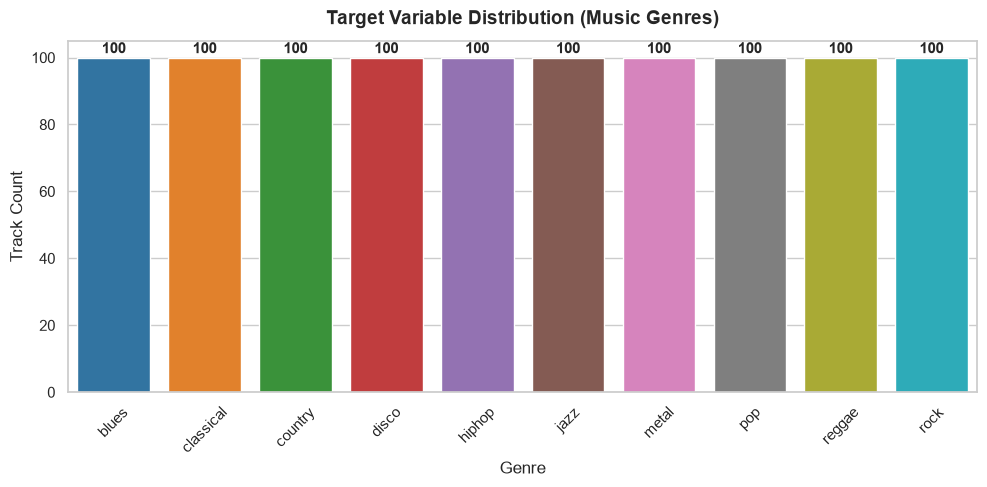

In [5]:
genre_counts = df['label'].value_counts()
print("Genre Class Counts:")
print(genre_counts)

plt.figure(figsize=(10, 5))
ax = sns.barplot(x=genre_counts.index, y=genre_counts.values, palette='tab10', hue=genre_counts.index, legend=False)
plt.title('Target Variable Distribution (Music Genres)', fontsize=14, weight='bold', pad=12)
plt.xlabel('Genre', fontsize=12)
plt.ylabel('Track Count', fontsize=12)
plt.xticks(rotation=45)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 6), textcoords='offset points', fontweight='bold')
plt.tight_layout()
plt.show()


## 5. Audio Feature Distributions & Visualizations
We plot feature distributions using histograms and kernel density estimates (KDE) to examine their characteristics across tracks.


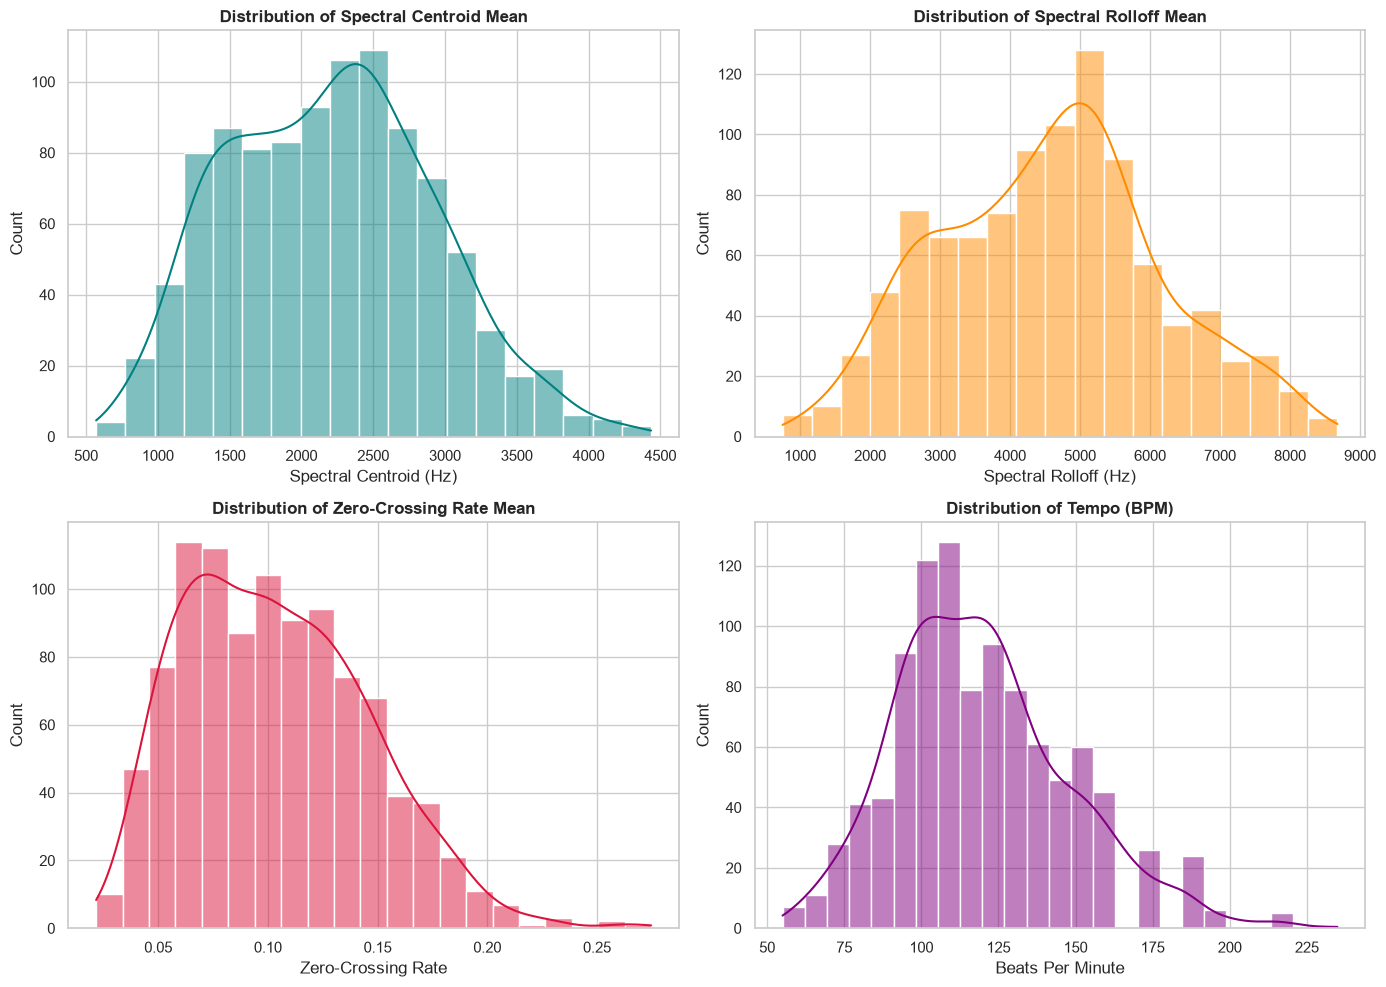

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(df['spectral_centroid_mean'], kde=True, ax=axes[0, 0], color='teal')
axes[0, 0].set_title('Distribution of Spectral Centroid Mean', weight='bold')
axes[0, 0].set_xlabel('Spectral Centroid (Hz)')

sns.histplot(df['rolloff_mean'], kde=True, ax=axes[0, 1], color='darkorange')
axes[0, 1].set_title('Distribution of Spectral Rolloff Mean', weight='bold')
axes[0, 1].set_xlabel('Spectral Rolloff (Hz)')

sns.histplot(df['zero_crossing_rate_mean'], kde=True, ax=axes[1, 0], color='crimson')
axes[1, 0].set_title('Distribution of Zero-Crossing Rate Mean', weight='bold')
axes[1, 0].set_xlabel('Zero-Crossing Rate')

sns.histplot(df['tempo'], kde=True, ax=axes[1, 1], color='purple')
axes[1, 1].set_title('Distribution of Tempo (BPM)', weight='bold')
axes[1, 1].set_xlabel('Beats Per Minute')

plt.tight_layout()
plt.show()


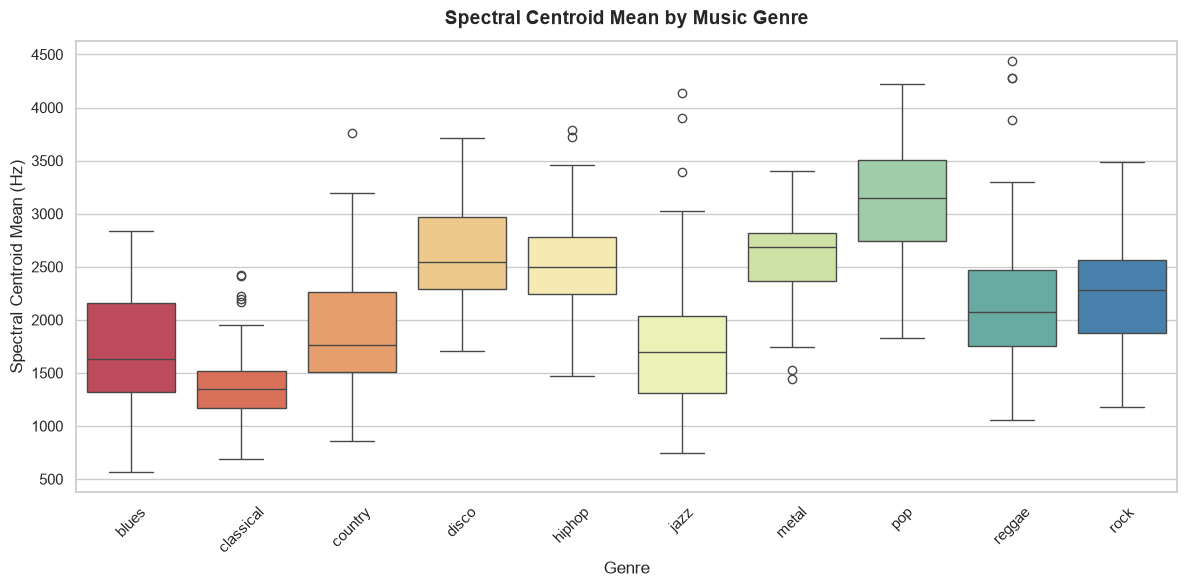

In [7]:
plt.figure(figsize=(12, 6))
sns.boxplot(x='label', y='spectral_centroid_mean', data=df, palette='Spectral', hue='label', legend=False)
plt.title('Spectral Centroid Mean by Music Genre', fontsize=14, weight='bold', pad=12)
plt.xlabel('Genre', fontsize=12)
plt.ylabel('Spectral Centroid Mean (Hz)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


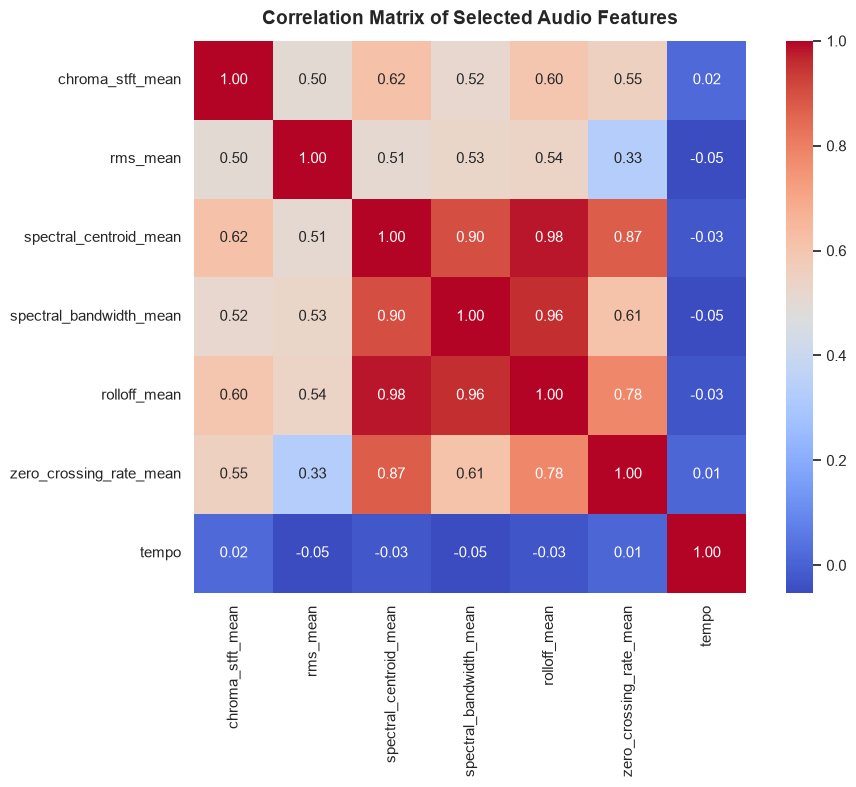

In [8]:
plt.figure(figsize=(10, 8))
corr = df[selected_features].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', cbar=True, square=True)
plt.title('Correlation Matrix of Selected Audio Features', fontsize=14, weight='bold', pad=12)
plt.tight_layout()
plt.show()


## 6. Key Findings & Preprocessing Recommendations
1. **Balanced Classes**: The dataset is perfectly balanced with exactly 100 audio tracks per genre across 10 genres (1,000 samples total). Macro-averaging is appropriate and ensures unbiased evaluation.
2. **Data Cleanliness**: Zero missing values detected across all 60 columns.
3. **Feature Scale Discrepancies**: Features span vastly different magnitudes (e.g., `spectral_centroid_mean` ~1000s vs `zero_crossing_rate_mean` ~0.01-0.1). Scaling with `StandardScaler` is crucial for distance-sensitive algorithms like SVM and regularized Logistic Regression.
4. **Data Leakage Prevention**: Scalers and transformations must be fit exclusively on the training split (80%) and applied to the test split (20%).
